# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [2]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [3]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [4]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [5]:

import random
import numpy as np
import torch

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# 1. Двічі ДО виклику set_seed()
print("=== ДО set_seed() ===")

for i in range(2):
    number = random.randint(1, 100)
    numbers = list(range(10))
    random.shuffle(numbers)
    print(f"Спроба {i+1}: число = {number}, список = {numbers}")


# 2. Двічі З викликом set_seed() перед кожною генерацією
print("\n=== З set_seed() ===")

for i in range(2):
    set_seed()
    number = random.randint(1, 100)
    numbers = list(range(10))
    random.shuffle(numbers)
    print(f"Спроба {i+1}: число = {number}, список = {numbers}")


# 3. Двічі БЕЗ проміжного виклику set_seed()
print("\n=== БЕЗ повторного set_seed() ===")

set_seed()

for i in range(2):
    number = random.randint(1, 100)
    numbers = list(range(10))
    random.shuffle(numbers)
    print(f"Спроба {i+1}: число = {number}, список = {numbers}")


=== ДО set_seed() ===
Спроба 1: число = 92, список = [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]
Спроба 2: число = 44, список = [5, 7, 1, 9, 0, 8, 6, 3, 2, 4]

=== З set_seed() ===
Спроба 1: число = 82, список = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Спроба 2: число = 82, список = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]

=== БЕЗ повторного set_seed() ===
Спроба 1: число = 82, список = [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
Спроба 2: число = 76, список = [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]


### Висновок до вправи 1

У цій вправі я перевірила, як працює генерація випадкових чисел і перемішування списку.

Спочатку, без використання `set_seed()`, я отримала різні числа (42 і 67), а також різний порядок чисел у списках.

Коли я почала викликати `set_seed()` перед кожною спробою, результати стали однаковими — обидва рази випало число 82, а списки перемішалися в однаковому порядку.

Після цього я викликала `set_seed()` лише один раз і повторила генерацію двічі. Цього разу результати знову відрізнялися (82 і 76).

Таким чином, я зрозуміла, що `set_seed()` допомагає отримувати однакові результати при повторному запуску генерації. Це корисно, коли потрібно перевірити або порівняти результати роботи програми.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [6]:
import torch

device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)

if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [7]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [8]:
import numpy as np

# Створюю масив 3x4, заповнений нулями
zeros_arr = np.zeros((3, 4))

# Створюю масив 3x4, заповнений сімками
sevens_arr = np.full((3, 4), 7)

print("Масив із нулями:")
print(zeros_arr)
print("Розмір:", zeros_arr.shape)
print("Тип даних:", zeros_arr.dtype)

print("\nМасив із сімками:")
print(sevens_arr)
print("Розмір:", sevens_arr.shape)
print("Тип даних:", sevens_arr.dtype)

Масив із нулями:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
Розмір: (3, 4)
Тип даних: float64

Масив із сімками:
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]]
Розмір: (3, 4)
Тип даних: int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [9]:
# Створюю масив від 0 до 20 із кроком 2
arange_arr = np.arange(0, 20, 2)

# Створюю масив із 5 чисел від 0 до 1
linspace_arr = np.linspace(0, 1, 5)

print("Масив із кроком 2:")
print(arange_arr)

print("\nМасив із 5 рівномірно розподілених чисел:")
print(linspace_arr)

Масив із кроком 2:
[ 0  2  4  6  8 10 12 14 16 18]

Масив із 5 рівномірно розподілених чисел:
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [10]:
# Створюю одиничну матрицю 4x4
identity = np.eye(4)

# Створюю матрицю 3x3 з випадковими числами
random_ints = np.random.randint(0, 10, size=(3, 3))

print("Одинична матриця 4x4:")
print(identity)
print("Кількість вимірів:", identity.ndim)

print("\nМатриця з випадковими числами 3x3:")
print(random_ints)
print("Кількість вимірів:", random_ints.ndim)

Одинична матриця 4x4:
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Кількість вимірів: 2

Матриця з випадковими числами 3x3:
[[6 3 7]
 [4 6 9]
 [2 6 7]]
Кількість вимірів: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [11]:
# Оцінки студентів
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# Обчислюю середню оцінку
mean = np.mean(scores)

# Обчислюю стандартне відхилення
std = np.std(scores)

# Нормалізую оцінки
z_scores = (scores - mean) / std

print("Середня оцінка:", mean)
print("Стандартне відхилення:", std)
print("Z-scores:", z_scores)

Середня оцінка: 81.1
Стандартне відхилення: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [12]:
# Створюю масив із чисел від 1 до 12
arr = np.arange(1, 13)

# Перетворюю масив на матрицю 3x4
matrix = arr.reshape(3, 4)

# Обчислюю суму кожного рядка
row_sums = matrix.sum(axis=1)

# Обчислюю суму кожного стовпця
col_sums = matrix.sum(axis=0)

print("Матриця 3x4:")
print(matrix)

print("\nСума по рядках:", row_sums)
print("Сума по стовпцях:", col_sums)

Матриця 3x4:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]

Сума по рядках: [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [13]:
# Створюю таблицю студентів та їхніх оцінок
df = pd.DataFrame({
    "name": ["Анна", "Марія", "Олена", "Ірина", "Софія",
             "Катерина", "Юлія", "Дарина"],
    "score": [95, 78, 88, 67, 92, 74, 85, 60]
})

# Залишаю студентів, які набрали більше 80 балів
# та сортую їх за спаданням оцінки
top = df[df["score"] > 80].sort_values(
    by="score", ascending=False
)

print("Студенти, які набрали більше 80 балів:")
print(top)

Студенти, які набрали більше 80 балів:
    name  score
0   Анна     95
4  Софія     92
2  Олена     88
6   Юлія     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [14]:
# Додаю колонку з літерними оцінками
df["grade"] = np.where(
    df["score"] >= 90, "A",
    np.where(df["score"] >= 75, "B", "C")
)

print("Таблиця студентів з оцінками:")
print(df)

Таблиця студентів з оцінками:
       name  score grade
0      Анна     95     A
1     Марія     78     B
2     Олена     88     B
3     Ірина     67     C
4     Софія     92     A
5  Катерина     74     C
6      Юлія     85     B
7    Дарина     60     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [15]:
import torch

# Створюю тензор 2x3, заповнений нулями
zeros_t = torch.zeros((2, 3))

# Створюю тензор 2x3, заповнений сімками
sevens_t = torch.full((2, 3), 7)

print("Тензор із нулями:")
print(zeros_t)
print("Розмір:", zeros_t.shape)
print("Тип даних:", zeros_t.dtype)

print("\nТензор із сімками:")
print(sevens_t)
print("Розмір:", sevens_t.shape)
print("Тип даних:", sevens_t.dtype)

Тензор із нулями:
tensor([[0., 0., 0.],
        [0., 0., 0.]])
Розмір: torch.Size([2, 3])
Тип даних: torch.float32

Тензор із сімками:
tensor([[7, 7, 7],
        [7, 7, 7]])
Розмір: torch.Size([2, 3])
Тип даних: torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [16]:
# Створюю тензор із числами від 0 до 20 з кроком 2
arange_t = torch.arange(0, 20, 2)

# Створюю тензор із 5 рівномірно розподілених чисел
linspace_t = torch.linspace(0, 1, 5)

print("Тензор із кроком 2:")
print(arange_t)

print("\nТензор із 5 рівномірно розподілених чисел:")
print(linspace_t)

Тензор із кроком 2:
tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])

Тензор із 5 рівномірно розподілених чисел:
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [17]:
# Створюю тензор зі звичайного списку
from_list = torch.tensor([[1, 2], [3, 4]])

# Створюю тензор 3x3 з випадковими числами
random_t = torch.rand(3, 3)

print("Тензор зі списку:")
print(from_list)
print("Форма:", from_list.shape)
print("Тип даних:", from_list.dtype)
print("Кількість вимірів:", from_list.ndim)

print("\nТензор із випадковими числами:")
print(random_t)
print("Форма:", random_t.shape)
print("Тип даних:", random_t.dtype)
print("Кількість вимірів:", random_t.ndim)

Тензор зі списку:
tensor([[1, 2],
        [3, 4]])
Форма: torch.Size([2, 2])
Тип даних: torch.int64
Кількість вимірів: 2

Тензор із випадковими числами:
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])
Форма: torch.Size([3, 3])
Тип даних: torch.float32
Кількість вимірів: 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [18]:
import torch

# Початкове значення
n = 5.0

# Створюю тензор з можливістю обчислення градієнта
x = torch.tensor(n, requires_grad=True)

# Обчислюю квадрат числа
y = x ** 2

# Обчислюю градієнт автоматично
y.backward()

# Порівнюю результати
print("Значення x:", x.item())
print("Значення y:", y.item())
print("Градієнт PyTorch:", x.grad.item())
print("Градієнт за формулою:", 2 * n)

Значення x: 5.0
Значення y: 25.0
Градієнт PyTorch: 10.0
Градієнт за формулою: 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [19]:
import torch

# Початкове значення x
x = torch.tensor(0.0, requires_grad=True)

# Швидкість навчання
lr = 0.1

# Виконую 20 кроків градієнтного спуску
for i in range(20):

    # Обчислюю значення функції
    loss = (x - 3) ** 2 + 5

    # Обчислюю градієнт
    loss.backward()

    # Оновлюю значення x
    with torch.no_grad():
        x -= lr * x.grad

    # Очищаю градієнт перед наступним кроком
    x.grad.zero_()

    print(f"Крок {i+1}: x = {x.item():.4f}")

print(f"\nКінцеве значення x = {x.item():.4f}")
print("Мінімум функції знаходиться при x = 3")

Крок 1: x = 0.6000
Крок 2: x = 1.0800
Крок 3: x = 1.4640
Крок 4: x = 1.7712
Крок 5: x = 2.0170
Крок 6: x = 2.2136
Крок 7: x = 2.3709
Крок 8: x = 2.4967
Крок 9: x = 2.5973
Крок 10: x = 2.6779
Крок 11: x = 2.7423
Крок 12: x = 2.7938
Крок 13: x = 2.8351
Крок 14: x = 2.8681
Крок 15: x = 2.8944
Крок 16: x = 2.9156
Крок 17: x = 2.9324
Крок 18: x = 2.9460
Крок 19: x = 2.9568
Крок 20: x = 2.9654

Кінцеве значення x = 2.9654
Мінімум функції знаходиться при x = 3


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

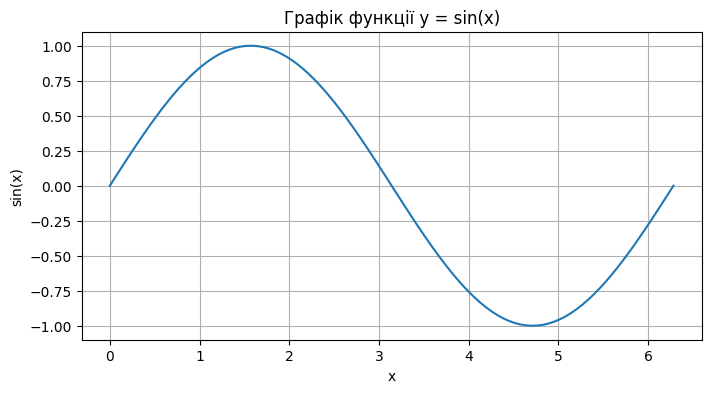

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Створюю 100 точок від 0 до 2π
xs = np.linspace(0, 2 * np.pi, 100)

# Обчислюю значення синуса
ys = np.sin(xs)

# Будую графік
plt.figure(figsize=(8, 4))
plt.plot(xs, ys)

# Додаю назву та підписи
plt.title("Графік функції y = sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")

# Додаю сітку
plt.grid(True)

# Показую графік
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

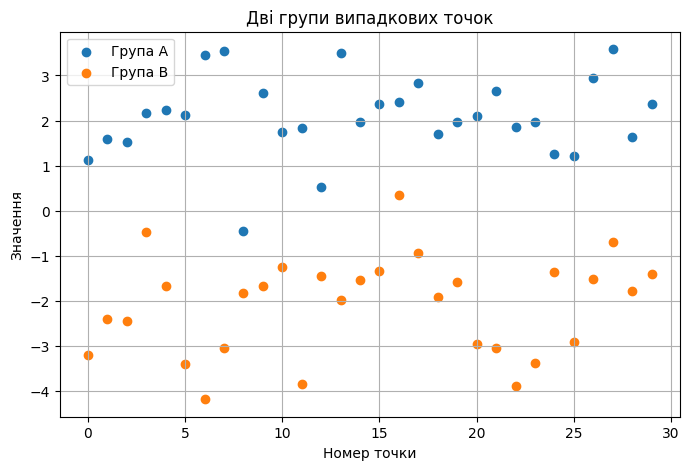

In [21]:
# Створюю дві групи випадкових чисел
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# Будую графік
plt.figure(figsize=(8, 5))

# Перша група точок
plt.scatter(range(30), group_a, color="C0", label="Група A")

# Друга група точок
plt.scatter(range(30), group_b, color="C1", label="Група B")

# Додаю назву та підписи
plt.title("Дві групи випадкових точок")
plt.xlabel("Номер точки")
plt.ylabel("Значення")

# Додаю легенду та сітку
plt.legend()
plt.grid(True)

# Показую графік
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [22]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

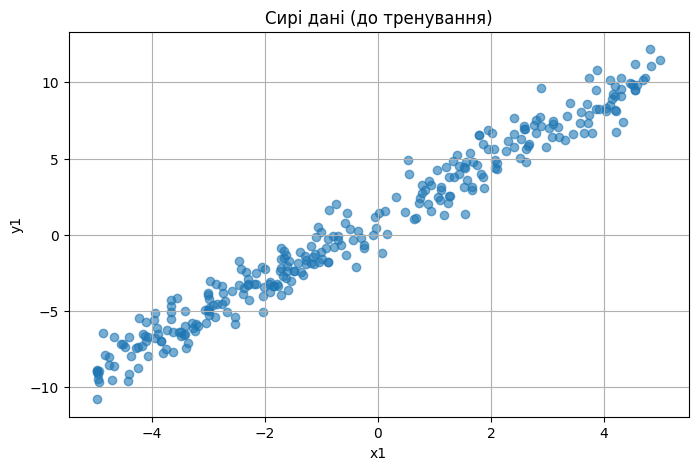

In [23]:
# Вправа 17. Візуалізація даних до навчання моделі

# Створюю графік
plt.figure(figsize=(8, 5))

# Відображаю дані, які були згенеровані раніше
plt.scatter(x1.numpy(), y1.numpy(), alpha=0.6)

# Додаю назву та підписи осей
plt.title("Сирі дані (до тренування)")
plt.xlabel("x1")
plt.ylabel("y1")

# Додаю сітку
plt.grid(True)

# Показую графік
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [24]:
# Випадково перемішую індекси даних
indices = torch.randperm(TASK1_N)

# Перемішую x та y в однаковому порядку
x_shuffled = x1[indices]
y_shuffled = y1[indices]

# Визначаю кількість даних для кожної групи
train_size = int(TASK1_N * 0.70)
val_size = int(TASK1_N * 0.15)

# Дані для навчання (70%)
x_train1 = x_shuffled[:train_size]
y_train1 = y_shuffled[:train_size]

# Дані для перевірки (15%)
x_val1 = x_shuffled[train_size:train_size + val_size]
y_val1 = y_shuffled[train_size:train_size + val_size]

# Дані для тестування (15%)
x_test1 = x_shuffled[train_size + val_size:]
y_test1 = y_shuffled[train_size + val_size:]

# Перевіряю кількість даних
print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [25]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


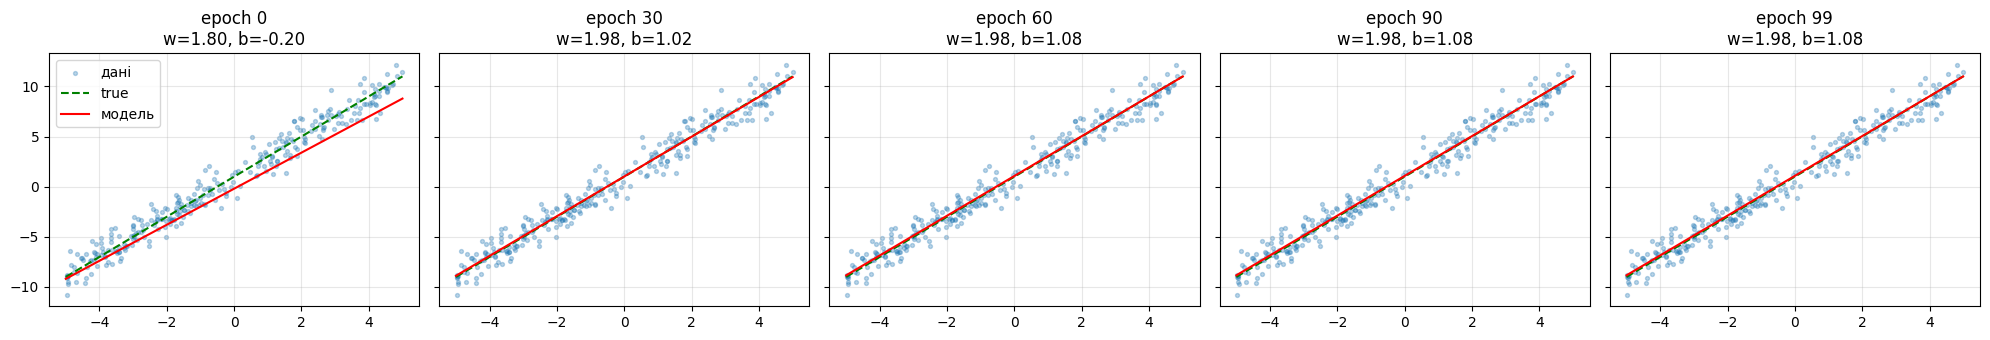

In [26]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

### Вправа 20. Залежність результату тесту від часу підготовки

Для цієї вправи я вирішила дослідити, як кількість годин підготовки може впливати на результат тесту.

Я припустила, що без підготовки студент може отримати приблизно 30 балів, а кожна додаткова година навчання підвищує результат у середньому на 6 балів.

Тому для своєї моделі я вибрала такі значення:
- **w = 6** — на стільки балів у середньому зростає результат за одну годину підготовки.
- **b = 30** — початковий результат без підготовки.

Такі значення здалися мені правдоподібними, оскільки навіть без додаткової підготовки можна мати певні знання, а більше часу на навчання зазвичай допомагає краще скласти тест.

При цьому результати не завжди будуть однаковими, тому я додала до даних випадковий шум. Він імітує ситуацію, коли студенти з однаковою кількістю годин підготовки можуть отримати різні бали.

CSV файл збережено: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
      hours      score
0  8.822693  80.150215
1  9.150040  80.058502
2  3.828638  57.328220
3  9.593057  87.080139
4  3.904482  55.445911

Розподіл даних:
210 45 45
Епоха 100: Train loss = 96.9986, Val loss = 123.0420
Епоха 200: Train loss = 47.1235, Val loss = 63.9396
Епоха 300: Train loss = 30.3141, Val loss = 42.3151
Епоха 400: Train loss = 24.6489, Val loss = 34.0371
Епоха 500: Train loss = 22.7395, Val loss = 30.6724
Епоха 600: Train loss = 22.0960, Val loss = 29.2048
Епоха 700: Train loss = 21.8791, Val loss = 28.5164
Епоха 800: Train loss = 21.8060, Val loss = 28.1720
Епоха 900: Train loss = 21.7814, Val loss = 27.9906
Епоха 1000: Train loss = 21.7731, Val loss = 27.8916

Результати навчання:
Справжній w: 6.0
Навчений w: 6.127655982971191
Справжній b: 30.0
Навчений b: 29.563907623291016
Test MSE: 29.881847381591797


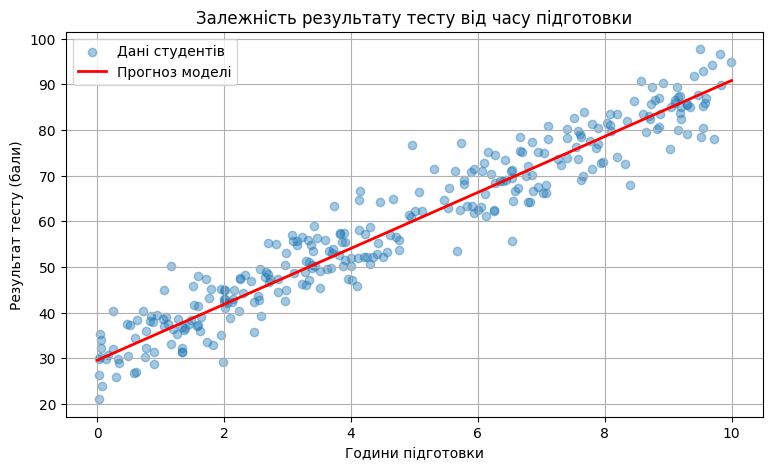

In [27]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Фіксую випадковість
np.random.seed(42)
torch.manual_seed(42)

# 1. Створюю дані
TRUE_W = 6.0
TRUE_B = 30.0
N = 300

# Кількість годин підготовки від 0 до 10
x = torch.rand(N, 1) * 10

# Додаю випадкові відхилення
noise = torch.randn(N, 1) * 5

# Обчислюю результати тесту
y = TRUE_W * x + TRUE_B + noise
y = torch.clamp(y, 0, 100)

# 2. Зберігаю дані у CSV
df_custom = pd.DataFrame({
    "hours": x.squeeze().numpy(),
    "score": y.squeeze().numpy()
})

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

csv_path = os.path.join(ARTIFACT_DIR, "dataset.csv")
df_custom.to_csv(csv_path, index=False)

print("CSV файл збережено:", csv_path)
print(df_custom.head())


# 3. Функція для розподілу даних
def split_data(x, y):
    n = len(x)
    indices = torch.randperm(n)

    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_idx = indices[:train_end]
    val_idx = indices[train_end:val_end]
    test_idx = indices[val_end:]

    return (
        x[train_idx], y[train_idx],
        x[val_idx], y[val_idx],
        x[test_idx], y[test_idx]
    )


# 4. Функція навчання моделі
def train_model(x_train, y_train, x_val, y_val,
                epochs=1000, lr=0.01):

    model = torch.nn.Linear(1, 1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    for epoch in range(epochs):
        model.train()

        optimizer.zero_grad()

        prediction = model(x_train)
        loss = loss_fn(prediction, y_train)

        loss.backward()
        optimizer.step()

        if (epoch + 1) % 100 == 0:
            model.eval()

            with torch.no_grad():
                val_prediction = model(x_val)
                val_loss = loss_fn(val_prediction, y_val)

            print(
                f"Епоха {epoch+1}: "
                f"Train loss = {loss.item():.4f}, "
                f"Val loss = {val_loss.item():.4f}"
            )

    return model


# 5. Розділяю дані
x_train, y_train, x_val, y_val, x_test, y_test = split_data(x, y)

print("\nРозподіл даних:")
print(len(x_train), len(x_val), len(x_test))


# 6. Навчаю модель
model_custom = train_model(
    x_train, y_train,
    x_val, y_val,
    epochs=1000,
    lr=0.01
)


# 7. Перевіряю модель на тестових даних
model_custom.eval()

with torch.no_grad():
    test_prediction = model_custom(x_test)
    test_loss = torch.nn.functional.mse_loss(
        test_prediction, y_test
    )

print("\nРезультати навчання:")
print("Справжній w:", TRUE_W)
print("Навчений w:", model_custom.weight.item())
print("Справжній b:", TRUE_B)
print("Навчений b:", model_custom.bias.item())
print("Test MSE:", test_loss.item())


# 8. Будую графік
plt.figure(figsize=(9, 5))

plt.scatter(
    x.numpy(),
    y.numpy(),
    alpha=0.4,
    label="Дані студентів"
)

x_line = torch.linspace(0, 10, 100).unsqueeze(1)

with torch.no_grad():
    y_line = model_custom(x_line)

plt.plot(
    x_line.numpy(),
    y_line.numpy(),
    color="red",
    linewidth=2,
    label="Прогноз моделі"
)

plt.title("Залежність результату тесту від часу підготовки")
plt.xlabel("Години підготовки")
plt.ylabel("Результат тесту (бали)")
plt.legend()
plt.grid(True)
plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [28]:

import os
import torch

# Папка для збереження моделі
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Зберігаю навчену модель
model_path = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(model_custom.state_dict(), model_path)

print("Модель успішно збережена!")
print("Файл:", model_path)

# Перевіряю, чи файл існує
print("Файл існує:", os.path.exists(model_path))

Модель успішно збережена!
Файл: /content/drive/MyDrive/ai_systems/lab1/model.pt
Файл існує: True


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [29]:
!pip install -q gradio

In [30]:
import gradio as gr
import torch
import os

# Завантажую збережену модель
model_path = "/content/drive/MyDrive/ai_systems/lab1/model.pt"

model = torch.nn.Linear(1, 1)
model.load_state_dict(
    torch.load(model_path, map_location="cpu", weights_only=True)
)
model.eval()

# Функція для прогнозування оцінки
def predict_score(hours):
    x = torch.tensor([[float(hours)]], dtype=torch.float32)

    with torch.no_grad():
        prediction = model(x).item()

    prediction = max(0, min(100, prediction))

    return round(prediction, 1)

# Створюю інтерфейс
app = gr.Interface(
    fn=predict_score,
    inputs=gr.Slider(
        minimum=0,
        maximum=10,
        step=0.5,
        label="Кількість годин підготовки"
    ),
    outputs=gr.Number(label="Прогнозована оцінка"),
    title="Прогноз результату тесту",
    description="Обери кількість годин підготовки, щоб дізнатися приблизний результат тесту."
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d2a85995d1bdb47819.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```